# Grad-CAM + JND: a small demo

Run on CPU. The first run downloads the VGG-16 weights.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if not (root / "api").is_dir():
    root = root.parent
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

from api.transformers.gradcam_jnd_watermark import GradCAMJNDWatermarkTransformer

file_names = [
    'cat',
    'dog',
    'fox'
]

originals = [
    Image.open(root / f"docs/assets/stegastamp/{name}.png").convert("RGB") 
    for name in file_names
]
logo = Image.new("L", (64, 64))
draw = ImageDraw.Draw(logo)
draw.rectangle((25, 8, 38, 55), fill=255)
draw.rectangle((8, 25, 55, 38), fill=255)

transformer = GradCAMJNDWatermarkTransformer(key="demo-key", device="cpu", ratio=4)

/Users/manoftheprincess/Helloworld/Uni/agh/sem2/watermarks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


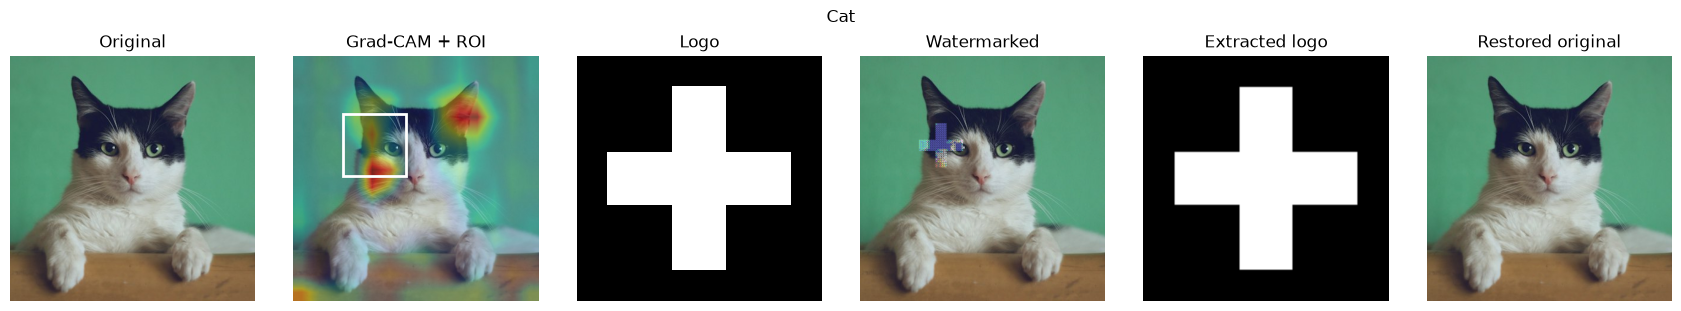

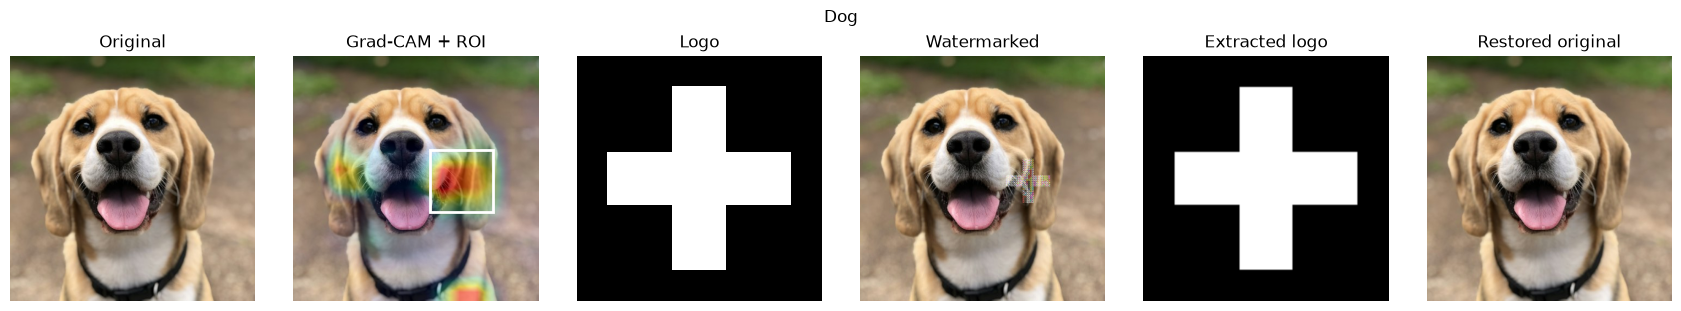

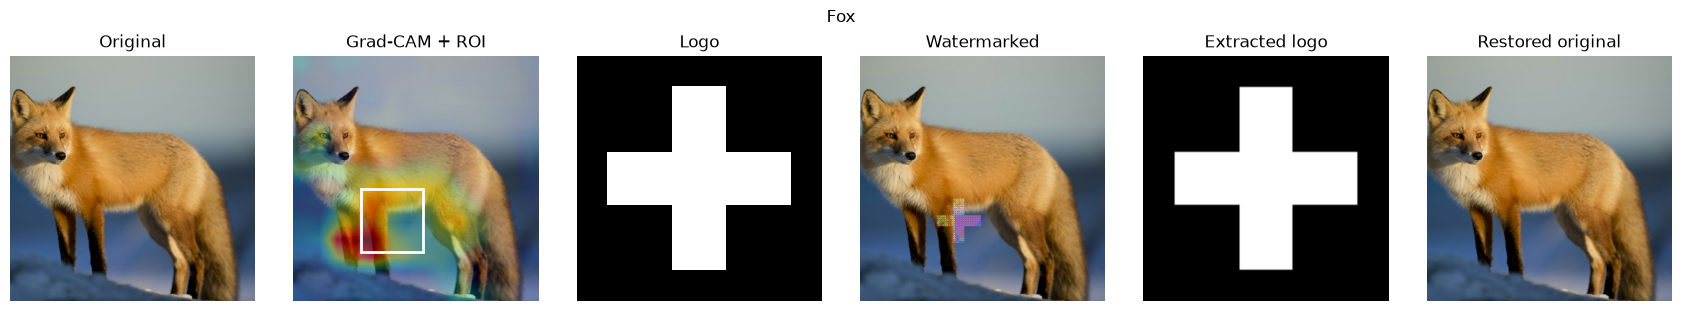

In [ ]:
from matplotlib.patches import Rectangle

for name, original in zip(file_names, originals):
    heatmap = transformer.gradcam(original, transformer.class_index)
    marked, report = transformer.embed(original, logo, heatmap=heatmap)
    restored, extracted_logo = transformer.extract(marked)
    assert np.array_equal(original, restored)

    fig, axes = plt.subplots(1, 6, figsize=(17, 3), layout="constrained")
    panels = [
        ("Original", original),
        ("Grad-CAM + ROI", original),
        ("Logo", logo),
        ("Watermarked", marked),
        ("Extracted logo", extracted_logo),
        ("Restored original", restored),
    ]
    for ax, (title, image) in zip(axes, panels):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")

    row, col, side = report["roi"]
    axes[1].imshow(heatmap, cmap="jet", alpha=0.6 * heatmap, vmin=0, vmax=1)
    axes[1].add_patch(Rectangle((col - 0.5, row - 0.5), side, side,
                                fill=False, edgecolor="white", linewidth=2))
    fig.suptitle(name.capitalize())
    plt.show()